### 1. Load and Preprocess the Dataset
We will load the `winequality-red.csv` dataset, inspect its columns, scale the features (since PCA is sensitive to data scales), and prepare it for analysis.

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset (using default comma separator as verified by the error output)
df = pd.read_csv('/content/winequality-red.csv')
display(df.head())
print(f"Dataset Shape: {df.shape}")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Dataset Shape: (1599, 12)


### 2. Standardize Features and Apply PCA
PCA is highly sensitive to the scale of the features. We will scale the features to have a mean of 0 and variance of 1, then apply PCA to project the data.

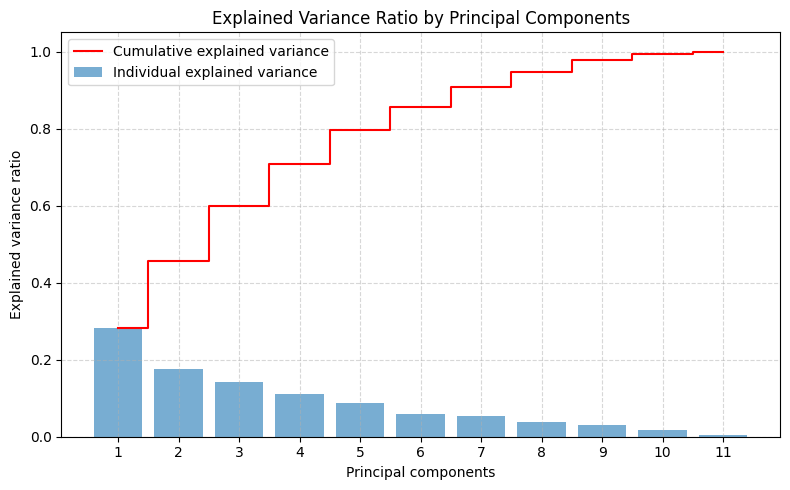

In [6]:
from sklearn.decomposition import PCA

# Strip any accidental whitespace from column names
df.columns = df.columns.str.strip()

# Separate features and target
X = df.drop(columns=['quality'])
y = df['quality']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calculate Cumulative Explained Variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Plot Explained Variance
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, alpha=0.6, align='center', label='Individual explained variance')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid', label='Cumulative explained variance', color='red')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal components')
plt.title('Explained Variance Ratio by Principal Components')
plt.xticks(range(1, len(pca.explained_variance_ratio_) + 1))
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 3. Visualize 2D Projection
Let's project the dataset onto the first two principal components and visualize the distribution, coloring the points by wine quality.

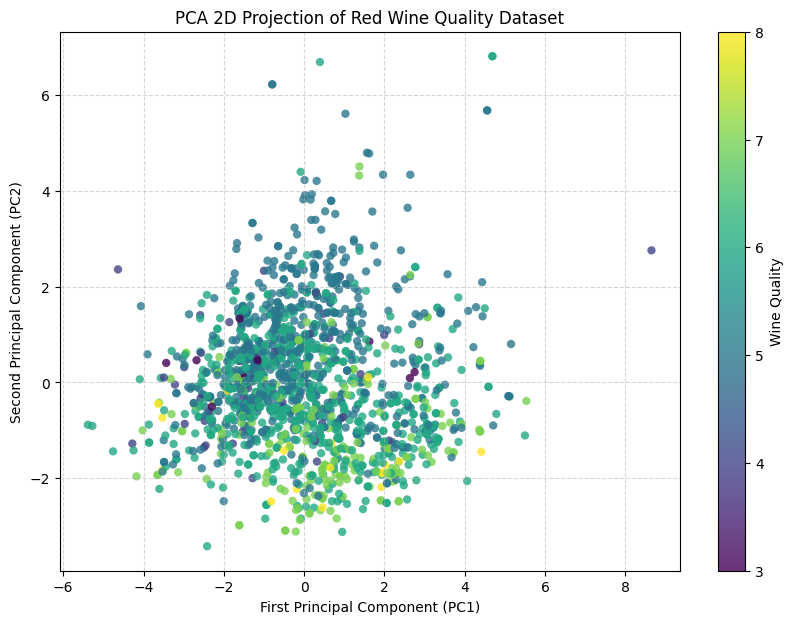

=== Feature Loadings for PC1 and PC2 ===


,PC1,PC2
fixed acidity,0.489314,-0.110503
volatile acidity,-0.238584,0.274930
citric acid,0.463632,-0.151791
residual sugar,0.146107,0.272080
chlorides,0.212247,0.148052
free sulfur dioxide,-0.036158,0.513567
total sulfur dioxide,0.023575,0.569487
density,0.395353,0.233575
pH,-0.438520,0.006711
sulphates,0.242921,-0.037554


In [7]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='viridis', alpha=0.8, edgecolor='none')
plt.colorbar(scatter, label='Wine Quality')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('PCA 2D Projection of Red Wine Quality Dataset')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Print loading scores for PC1 and PC2
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=['PC1', 'PC2'],
    index=X.columns
)
print("=== Feature Loadings for PC1 and PC2 ===")
display(loadings)